# Diabetes prediction

Code from the original project notebook. The scripts in this repository (`train.py`, `eda.py`, `diabetes/`) contain the same steps; see the README.

## Imports

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.linear_model import SGDClassifier

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC, SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, recall_score, make_scorer,roc_curve, auc, roc_auc_score
from sklearn.kernel_approximation import Nystroem, RBFSampler
from sklearn.linear_model import LogisticRegression

from sklearn.calibration import CalibratedClassifierCV



# Configure plots
%matplotlib inline
sns.set_style('whitegrid')


from collections import Counter
from imblearn.ensemble import BalancedRandomForestClassifier
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle

import joblib


## Data and exploration

In [ ]:
# Dataset: see data/README.md
df = pd.read_csv('../data/diabetes_012_health_indicators_BRFSS2015.csv')

In [ ]:
df.head()

,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


In [ ]:
#check for missing values
print('\nMissing values in each column:')
print(df.isnull().sum())


Missing values in each column:
Diabetes_012            0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64


In [ ]:
# Basic overview
print('Check the basic info of the dataset:')
display(df.info())

print('Statistical summary of numeric features:')
display(df.describe(include=[np.number]).T)

Check the basic info of the dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          253680 non-null  float64
 1   HighBP                253680 non-null  float64
 2   HighChol              253680 non-null  float64
 3   CholCheck             253680 non-null  float64
 4   BMI                   253680 non-null  float64
 5   Smoker                253680 non-null  float64
 6   Stroke                253680 non-null  float64
 7   HeartDiseaseorAttack  253680 non-null  float64
 8   PhysActivity          253680 non-null  float64
 9   Fruits                253680 non-null  float64
 10  Veggies               253680 non-null  float64
 11  HvyAlcoholConsump     253680 non-null  float64
 12  AnyHealthcare         253680 non-null  float64
 13  NoDocbcCost           253680 non-null  float64
 14  GenHlth        

None

Statistical summary of numeric features:


,count,mean,std,min,25%,50%,75%,max
Diabetes_012,253680.0,0.296921,0.698160,0.0,0.0,0.0,0.0,2.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


Numeric columns: ['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']


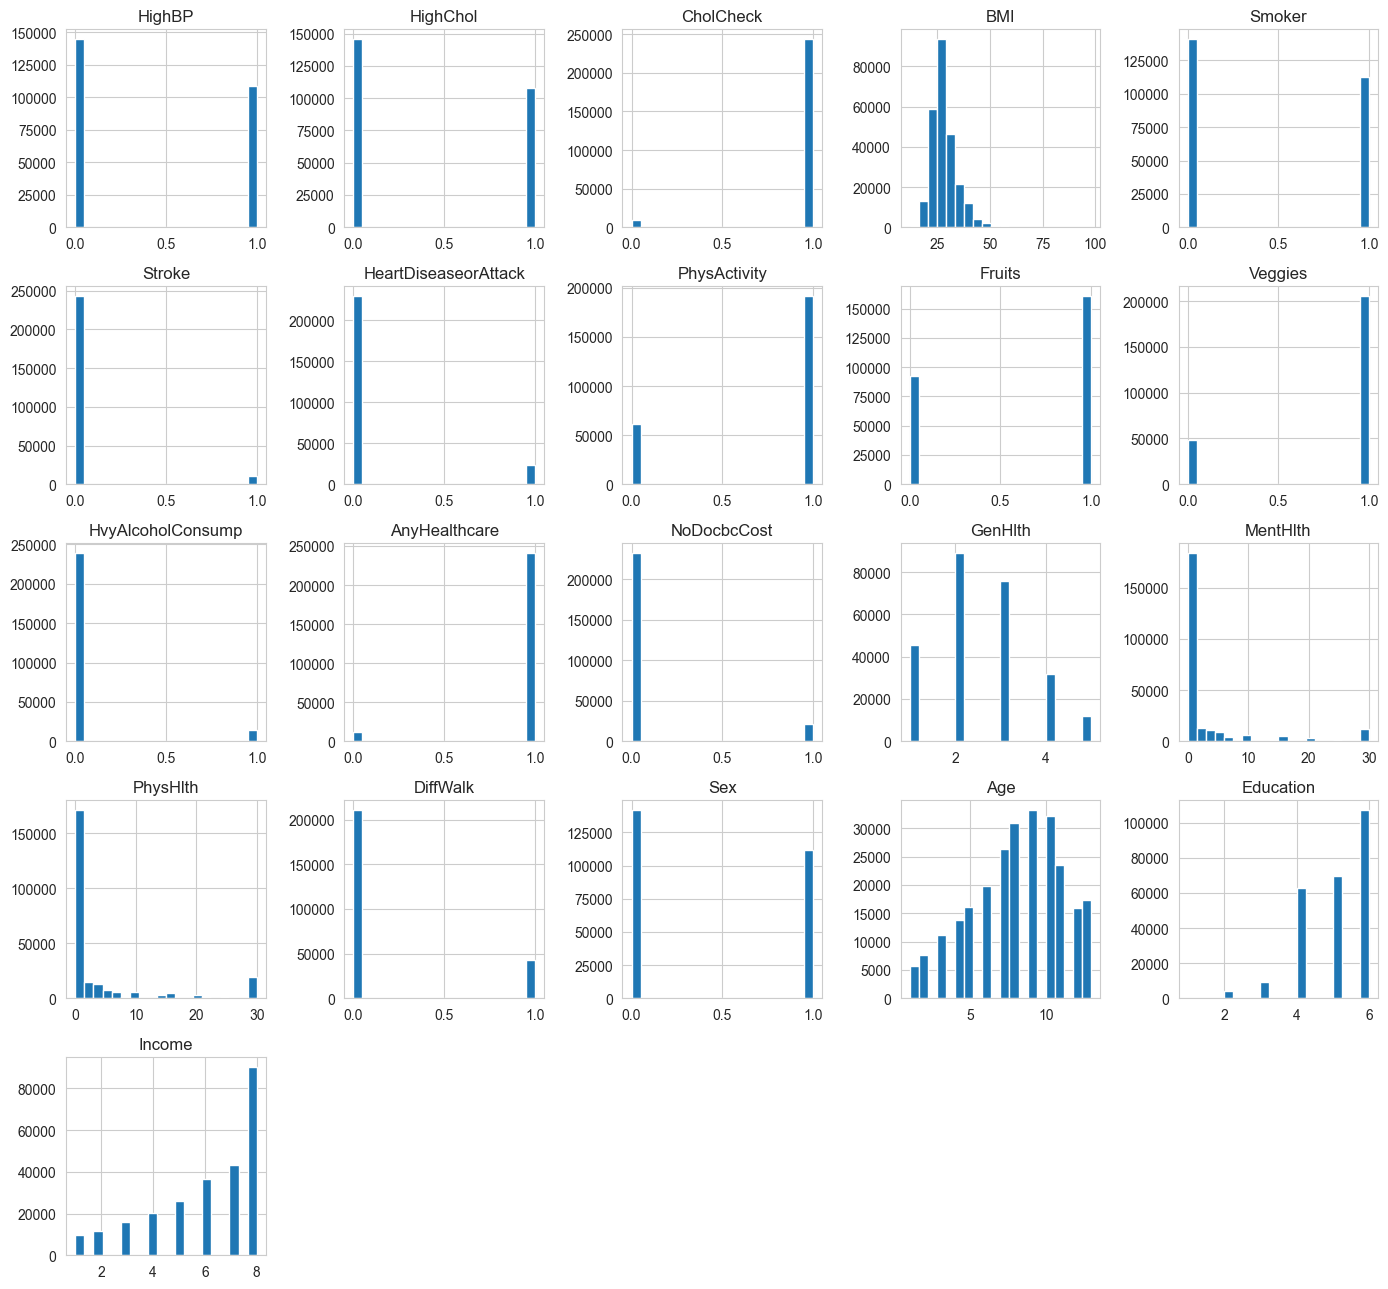

In [ ]:

# Histograms for numeric features
num_cols = df.select_dtypes(include=[np.number]).columns.tolist()
if 'Diabetes_012' in num_cols:
    num_cols.remove('Diabetes_012')
print('Numeric columns:', num_cols)
if len(num_cols)>0:
    df[num_cols].hist(bins=20, figsize=(14, int(0.5*len(num_cols))+3))
    plt.tight_layout()
    plt.show()
else:
    print('No numeric columns to plot histograms.')


In [ ]:
#define the features and target
X = df.drop('Diabetes_012', axis=1)
y = df['Diabetes_012']


In [ ]:
#check the shape of the dataset
df.shape

(253680, 22)

In [ ]:
print("X Shape  :  ",X.shape)
print("y Shape  :  ",y.shape)

X Shape  :   (253680, 21)
y Shape  :   (253680,)


In [ ]:
print("DataFrame Head  :  ")
print(X.head())

DataFrame Head  :  
   HighBP  HighChol  CholCheck   BMI  Smoker  Stroke  HeartDiseaseorAttack  \
0     1.0       1.0        1.0  40.0     1.0     0.0                   0.0   
1     0.0       0.0        0.0  25.0     1.0     0.0                   0.0   
2     1.0       1.0        1.0  28.0     0.0     0.0                   0.0   
3     1.0       0.0        1.0  27.0     0.0     0.0                   0.0   
4     1.0       1.0        1.0  24.0     0.0     0.0                   0.0   

   PhysActivity  Fruits  Veggies  ...  AnyHealthcare  NoDocbcCost  GenHlth  \
0           0.0     0.0      1.0  ...            1.0          0.0      5.0   
1           1.0     0.0      0.0  ...            0.0          1.0      3.0   
2           0.0     1.0      0.0  ...            1.0          1.0      5.0   
3           1.0     1.0      1.0  ...            1.0          0.0      2.0   
4           1.0     1.0      1.0  ...            1.0          0.0      2.0   

   MentHlth  PhysHlth  DiffWalk  Sex   Age

In [ ]:
print("Unique Classes  :  ",y.unique())

print("\nClass counts \n",y.value_counts())

print("\npositive class ratio = ", y.value_counts(normalize=True)[1])

Unique Classes  :   [0. 2. 1.]

Class counts 
 Diabetes_012
0.0    213703
2.0     35346
1.0      4631
Name: count, dtype: int64

positive class ratio =  0.018255282245348472


In [ ]:
#check the ratio of the target column
y.value_counts(normalize=True)

Diabetes_012
0.0    0.842412
2.0    0.139333
1.0    0.018255
Name: proportion, dtype: float64

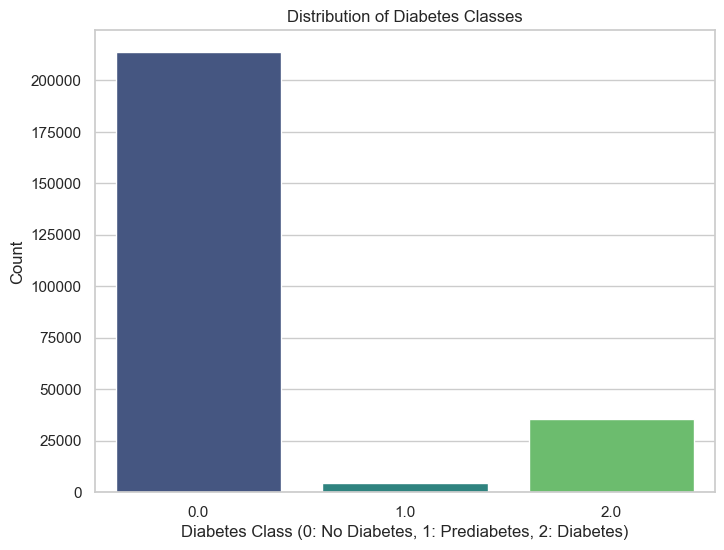

In [ ]:
#Create the graphs to visualize the data

# Set the style for seaborn
sns.set(style="whitegrid")

# Plot the distribution of the target variable
plt.figure(figsize=(8, 6))
sns.countplot(x=y, palette="viridis")
plt.title('Distribution of Diabetes Classes')
plt.xlabel('Diabetes Class (0: No Diabetes, 1: Prediabetes, 2: Diabetes)')
plt.ylabel('Count')
plt.show()

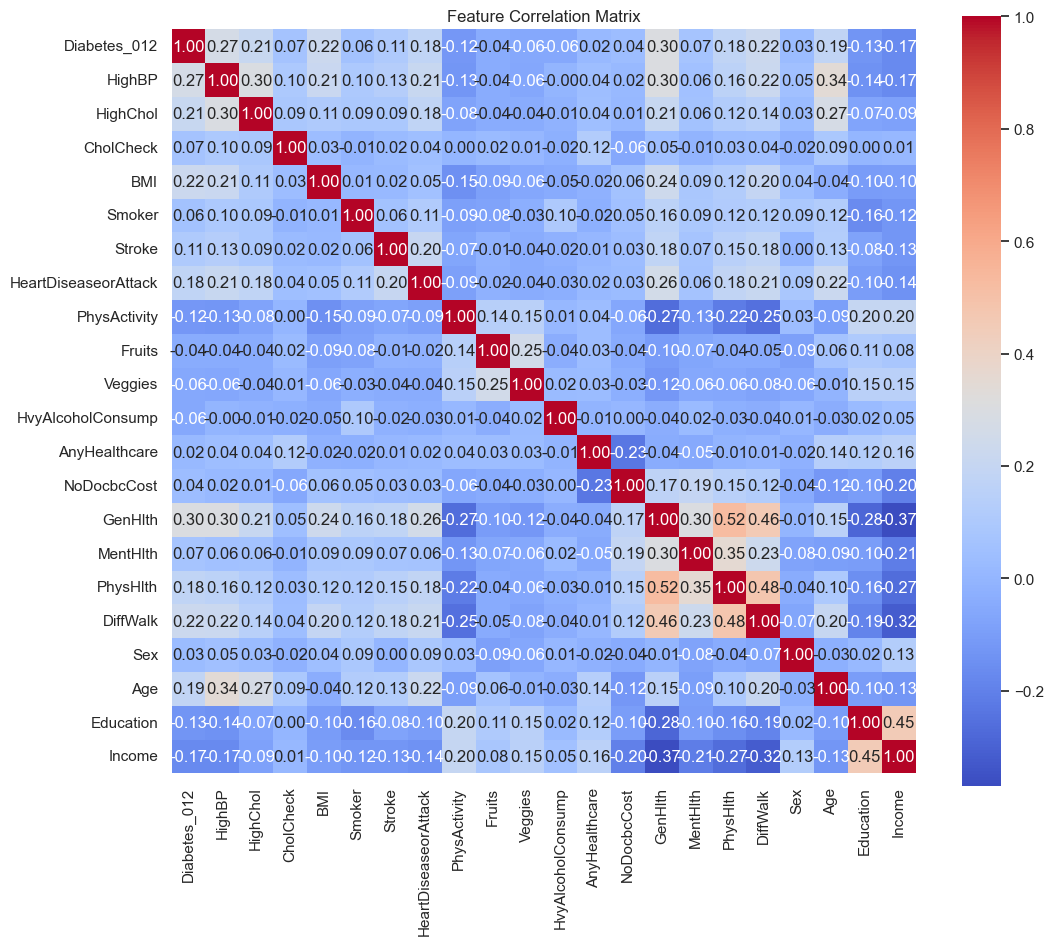

In [ ]:
#Graph to show correlation between features
plt.figure(figsize=(12, 10))
correlation_matrix = df.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True)
plt.title('Feature Correlation Matrix')
plt.show()

## Train/test split and preprocessing

In [ ]:
#split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
# stratify ensures the same distribution of classes in both sets

print('X_train Shape  :  ', X_train.shape)
print('\nX_test Shape  :  ', X_test.shape)
print('\ny_train Shape  :  ', y_train.shape)
print('\ny_test Shape  :  ', y_test.shape)

X_train Shape  :   (202944, 21)

X_test Shape  :   (50736, 21)

y_train Shape  :   (202944,)

y_test Shape  :   (50736,)


In [ ]:
def recall_for_class2(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=[2], average='macro')

recall2_scorer = make_scorer(recall_for_class2)

In [ ]:
preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),   # scale before SVM (important)
])

## 1. Support vector machines

In [ ]:
#FAST LINEAR SVM
pipe_lin = Pipeline([
    ("prep", preprocessor),
    ("clf", LinearSVC(max_iter=20000, random_state=42))
])

param_grid_lin = {
    "clf__C": [0.1, 1, 5],
    "clf__class_weight": ["balanced"]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gs_lin = GridSearchCV(pipe_lin, param_grid_lin, cv=cv,
                      scoring=recall2_scorer, n_jobs=-1, verbose=1)
gs_lin.fit(X_train, y_train)

y_pred_lin = gs_lin.predict(X_test)

In [ ]:
# FAST LINEAR SVM with SGDClassifier
pipe_sgd = Pipeline([
    ("prep", preprocessor),
    ("clf", SGDClassifier(loss="hinge", max_iter=20000, random_state=42))
])

# Convert C to alpha: alpha = 1 / (n_samples * C)
param_grid_sgd = {
    "clf__alpha": [1/(len(X_train)*C) for C in [0.1, 1, 5]],
    "clf__class_weight": ["balanced", None]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gs_sgd = GridSearchCV(pipe_sgd, param_grid_sgd, cv=cv,
                      scoring=recall2_scorer, n_jobs=-1, verbose=1)
gs_sgd.fit(X_train, y_train)

y_pred_sgd = gs_sgd.predict(X_test)

In [ ]:
# FAST APPROX-KERNEL SVM (NYSTROEM) with SGDClassifier
pipe_nys_sgd = Pipeline([
    ("prep", preprocessor),
    ("nys", Nystroem(kernel="rbf", n_components=300, random_state=42)),
    ("clf", SGDClassifier(loss="hinge", max_iter=20000, random_state=42))
])

# Convert C to alpha: alpha = 1 / (n_samples * C)
param_grid_nys_sgd = {
    "nys__gamma": [0.01, 0.1],
    "clf__alpha": [1/(len(X_train)*C) for C in [0.1, 1, 5]],
    "clf__class_weight": ["balanced", None]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gs_nys_sgd = GridSearchCV(pipe_nys_sgd, param_grid_nys_sgd, cv=cv,
                          scoring=recall2_scorer, n_jobs=-1, verbose=1)
gs_nys_sgd.fit(X_train, y_train)

y_pred_nys_sgd = gs_nys_sgd.predict(X_test)

### Evaluation

In [ ]:
# CONFUSION MATRIX PLOT
def plot_cm(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0,1,2])
    plt.figure(figsize=(6,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=["0 - No Diabetes", "1 - PreDiabetes", "2 - Diabetes"],
                yticklabels=["0 - No Diabetes", "1 - PreDiabetes", "2 - Diabetes"])
    plt.title(title)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

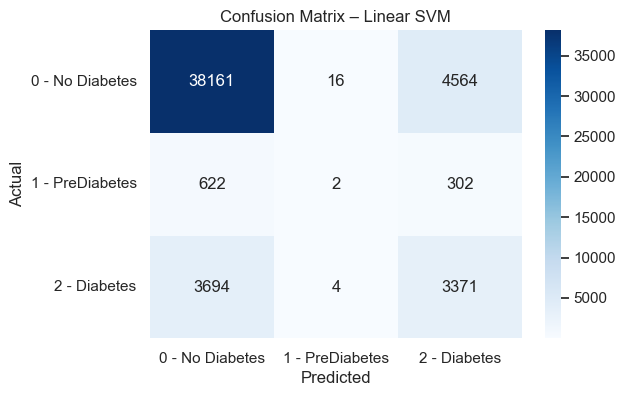

              precision    recall  f1-score   support

         0.0     0.8984    0.8928    0.8956     42741
         1.0     0.0909    0.0022    0.0042       926
         2.0     0.4093    0.4769    0.4405      7069

    accuracy                         0.8186     50736
   macro avg     0.4662    0.4573    0.4468     50736
weighted avg     0.8155    0.8186    0.8159     50736



In [ ]:
# Plot matrices
plot_cm(y_test, y_pred_lin, "Confusion Matrix – Linear SVM")
#plot_cm(y_test, y_pred_nys, "Confusion Matrix – Nystroem Approx RBF")

print(classification_report(y_test, y_pred_lin, digits=4))
#print(classification_report(y_test, y_pred_nys, digits=4))

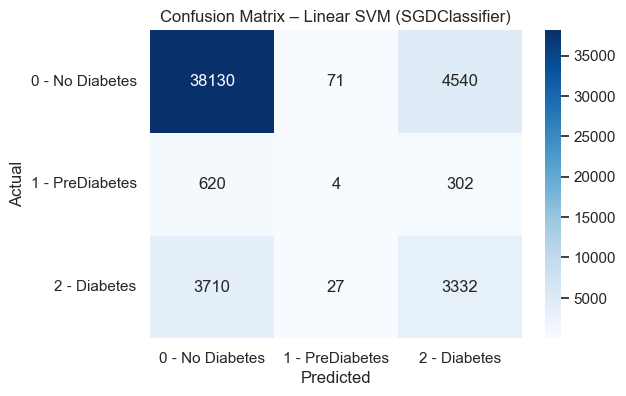

Classification Report – Linear SVM (SGDClassifier):
              precision    recall  f1-score   support

         0.0     0.8980    0.8921    0.8951     42741
         1.0     0.0392    0.0043    0.0078       926
         2.0     0.4076    0.4714    0.4372      7069

    accuracy                         0.8173     50736
   macro avg     0.4483    0.4559    0.4467     50736
weighted avg     0.8140    0.8173    0.8151     50736



In [ ]:
# Plot confusion matrices for SGDClassifier
plot_cm(y_test, y_pred_sgd, "Confusion Matrix – Linear SVM (SGDClassifier)")

# Print classification reports for SGDClassifier
print("Classification Report – Linear SVM (SGDClassifier):")
print(classification_report(y_test, y_pred_sgd, digits=4))




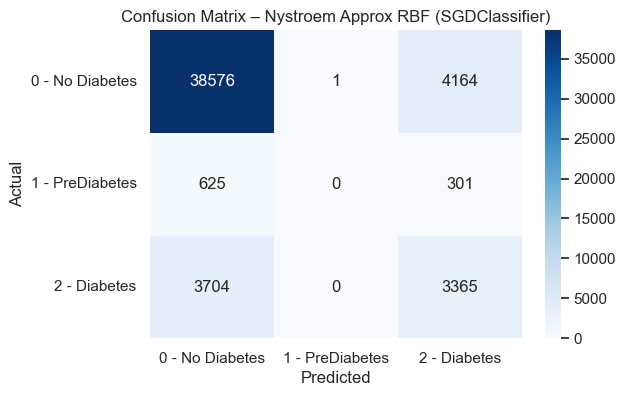

Classification Report – Nystroem Approx RBF (SGDClassifier):
              precision    recall  f1-score   support

         0.0     0.8991    0.9026    0.9008     42741
         1.0     0.0000    0.0000    0.0000       926
         2.0     0.4298    0.4760    0.4517      7069

    accuracy                         0.8267     50736
   macro avg     0.4430    0.4595    0.4508     50736
weighted avg     0.8173    0.8267    0.8218     50736



In [ ]:
plot_cm(y_test, y_pred_nys_sgd, "Confusion Matrix – Nystroem Approx RBF (SGDClassifier)")
print("Classification Report – Nystroem Approx RBF (SGDClassifier):")
print(classification_report(y_test, y_pred_nys_sgd, digits=4))

## 2. Logistic regression (final model)

In [ ]:


# Scale the features
# Logistic Regression is sensitive to feature scale; standardization improves convergence and performance.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Data loaded and scaled.")
print(f"Training shape: {X_train_scaled.shape}")
print(f"Test shape: {X_test_scaled.shape}")

Data loaded and scaled.
Training shape: (202944, 21)
Test shape: (50736, 21)


In [ ]:
# To achieve >90% recall for Diabetes, we use 'class_weight' optimization.
# Standard 'balanced' weights are not aggressive enough for 90% recall.
# We manually assign higher weights to Class 2 (Diabetes) to force the model to prioritize it.

# Weights explanation:
# Class 0 (No Diabetes): Weight 1 (Baseline)
# Class 1 (Prediabetes): Weight 10 (Attempt to boost visibility)
# Class 2 (Diabetes): Weight 20 (Heavily penalized for misses to maximize recall)

weights = {0: 1, 1: 10, 2: 20}

model = LogisticRegression(
    class_weight=weights,
    max_iter=1000,
    random_state=42,
    solver='lbfgs',
    multi_class='multinomial'
)

# Train the model
model.fit(X_train_scaled, y_train)

# Generate predictions
y_pred = model.predict(X_test_scaled)
y_score = model.predict_proba(X_test_scaled) # For ROC Curve

In [ ]:
# Save model and scaler
joblib.dump(model, "model.joblib")
joblib.dump(scaler, "scaler.joblib")

print("\nSaved 'model.joblib' and 'scaler.joblib' in current directory.")


Saved 'model.joblib' and 'scaler.joblib' in current directory.


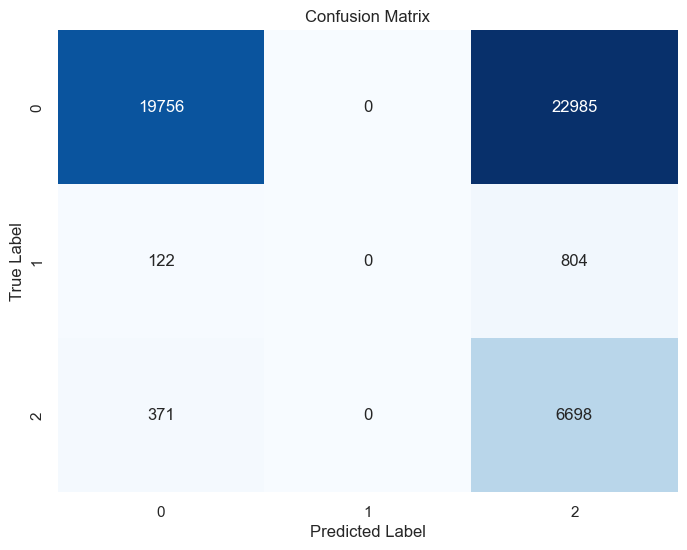


Model Accuracy: 52.14%

Classification Report:
               precision    recall  f1-score   support

 No Diabetes       0.98      0.46      0.63     42741
Pre-Diabetes       0.00      0.00      0.00       926
    Diabetes       0.22      0.95      0.36      7069

    accuracy                           0.52     50736
   macro avg       0.40      0.47      0.33     50736
weighted avg       0.85      0.52      0.58     50736



In [ ]:
# Plot Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

#Calculate and print the Accuracy Score
accuracy = accuracy_score(y_test, y_pred)
print(f"\nModel Accuracy: {accuracy * 100:.2f}%")


# Generate classification report
print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=['No Diabetes', 'Pre-Diabetes', 'Diabetes']))

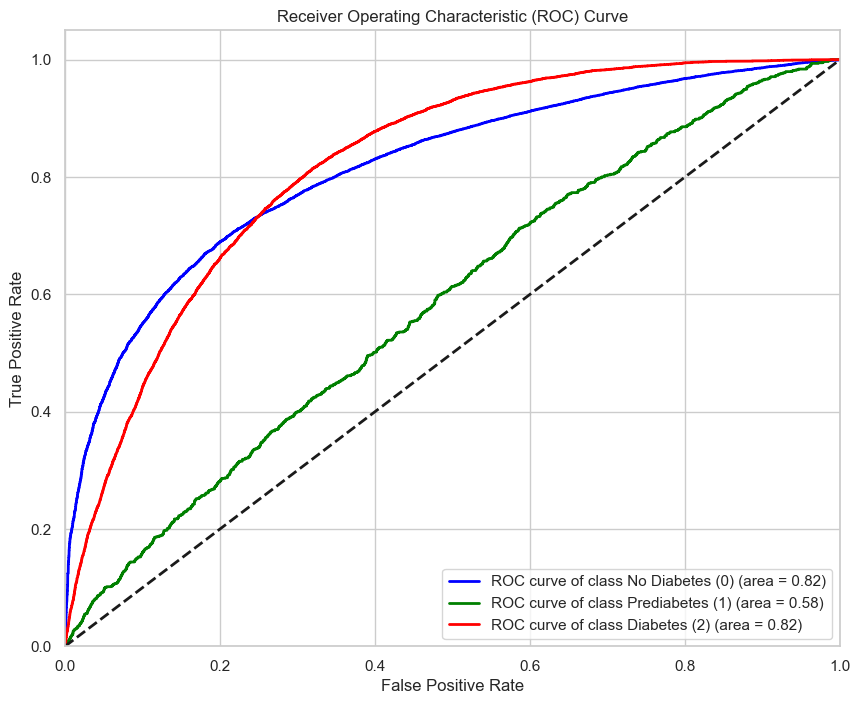


Weighted Average ROC-AUC Score: 0.8122


In [ ]:
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc, roc_auc_score
import seaborn as sns

# Binarize the output for multi-class ROC plotting
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Plot all ROC curves
plt.figure(figsize=(10, 8))
colors = ['blue', 'green', 'red']
labels = ['No Diabetes (0)', 'Prediabetes (1)', 'Diabetes (2)']

for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve of class {0} (area = {1:0.2f})'.format(labels[i], roc_auc[i]))

plt.plot([0, 1], [0, 1], 'k--', lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc="lower right")
plt.show()

#Print the weighted ROC-AUC score (Single number summary)
auc_score = roc_auc_score(y_test_bin, y_score, multi_class='ovr', average='weighted')
print(f"\nWeighted Average ROC-AUC Score: {auc_score:.4f}")

## 3. Random forest

In [ ]:
#FEATURE ENGINEERING
#Risk Interaction: Combining BMI and Age
#High BMI + Old Age is VERY dangerous
df['Risk_Interaction'] = df['BMI'] * df['Age']

#Heart Risk Factor
df['Heart_Risk'] = df['HighBP'] + df['HighChol'] + df['HeartDiseaseorAttack']

#Overall Health Struggle
df['Health_Struggle'] = df['MentHlth'] + df['PhysHlth']

print("New features added! Dataset shape is now:", df.shape)
print(df[['Risk_Interaction', 'Heart_Risk', 'Health_Struggle']].head())

New features added! Dataset shape is now: (253680, 25)
   Risk_Interaction  Heart_Risk  Health_Struggle
0             360.0         2.0             33.0
1             175.0         0.0              0.0
2             252.0         2.0             60.0
3             297.0         1.0              0.0
4             264.0         2.0              3.0


In [ ]:
#Separate the dataframe into the 3 classes
class_0 = df[df['Diabetes_012'] == 0]
class_1 = df[df['Diabetes_012'] == 1]
class_2 = df[df['Diabetes_012'] == 2]

#Class 2 (Diabetes) anchor size (~35,000)
target_count = len(class_2)
print(f"Target count per class: {target_count}")

#Downsample Class 0
class_0_balanced = class_0.sample(target_count, random_state=42)

#Upsample Class 1
class_1_balanced = class_1.sample(target_count, replace=True, random_state=42)

#Class 2 as is
class_2_balanced = class_2

#Combine
df_balanced = pd.concat([class_0_balanced, class_1_balanced, class_2_balanced], axis=0)

print("Original dataset shape:", df.shape)
print("New balanced dataset shape:", df_balanced.shape)
print("\nNew counts:\n", df_balanced['Diabetes_012'].value_counts())

Target count per class: 35346
Original dataset shape: (253680, 25)
New balanced dataset shape: (106038, 25)

New counts:
 Diabetes_012
0.0    35346
1.0    35346
2.0    35346
Name: count, dtype: int64


In [ ]:
#Define X (features) and y (target) using the NEW balanced dataframe
X = df_balanced.drop('Diabetes_012', axis=1)
y = df_balanced['Diabetes_012']

#Re-split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print('New X_train Shape  :  ', X_train.shape)
print('New X_test Shape   :  ', X_test.shape)
print('New y_train Shape  :  ', y_train.shape)
print('New y_test Shape   :  ', y_test.shape)

New X_train Shape  :   (84830, 24)
New X_test Shape   :   (21208, 24)
New y_train Shape  :   (84830,)
New y_test Shape   :   (21208,)


In [ ]:
#Import the Random Forest Classifier
from sklearn.ensemble import RandomForestClassifier

#Initialize the model
rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)

print("Model initialized successfully!")

Model initialized successfully!


In [ ]:
#Train the model on the training data
print("Training started... please wait.")

rf_model.fit(X_train, y_train)

print("Training finished! The model has learned the patterns.")

Training started... please wait.
Training finished! The model has learned the patterns.


In [ ]:
#Make predictions on the test set
y_pred = rf_model.predict(X_test)

print("Predictions generated!")

#First 10 guesses the model made:
print("First 10 predictions:", y_pred[:10])

#Actual correct answers for those same 10 people:
print("First 10 actual values:", y_test[:10].values)

Predictions generated!
First 10 predictions: [2. 1. 0. 2. 1. 2. 1. 2. 1. 2.]
First 10 actual values: [2. 1. 0. 2. 1. 2. 1. 2. 1. 2.]


Model Accuracy: 82.14%


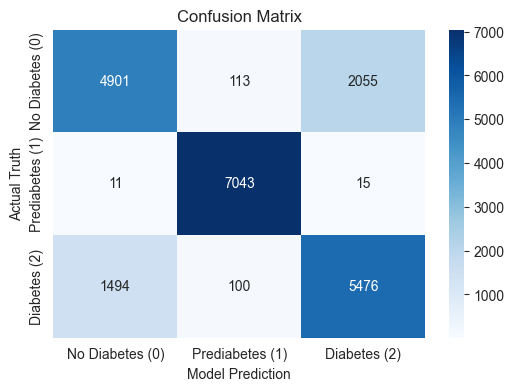


--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

 No Diabetes       0.77      0.69      0.73      7069
Pre-diabetes       0.97      1.00      0.98      7069
    Diabetes       0.73      0.77      0.75      7070

    accuracy                           0.82     21208
   macro avg       0.82      0.82      0.82     21208
weighted avg       0.82      0.82      0.82     21208



In [ ]:

#Calculate and print the Accuracy Score
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%")

#Create the Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
#Visualize the Confusion Matrix using a Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=['No Diabetes (0)', 'Prediabetes (1)', 'Diabetes (2)'],
            yticklabels=['No Diabetes (0)', 'Prediabetes (1)', 'Diabetes (2)'])
plt.title('Confusion Matrix')
plt.ylabel('Actual Truth')
plt.xlabel('Model Prediction')
plt.show()

#Detailed Report (Precision, Recall, F1)
print("\n--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, target_names=['No Diabetes', 'Pre-diabetes', 'Diabetes']))


--- DETAILED CLASSIFICATION REPORT ---
                  precision    recall  f1-score   support

 No Diabetes (0)       0.77      0.69      0.73      7069
Pre-diabetes (1)       0.97      1.00      0.98      7069
    Diabetes (2)       0.73      0.77      0.75      7070

        accuracy                           0.82     21208
       macro avg       0.82      0.82      0.82     21208
    weighted avg       0.82      0.82      0.82     21208



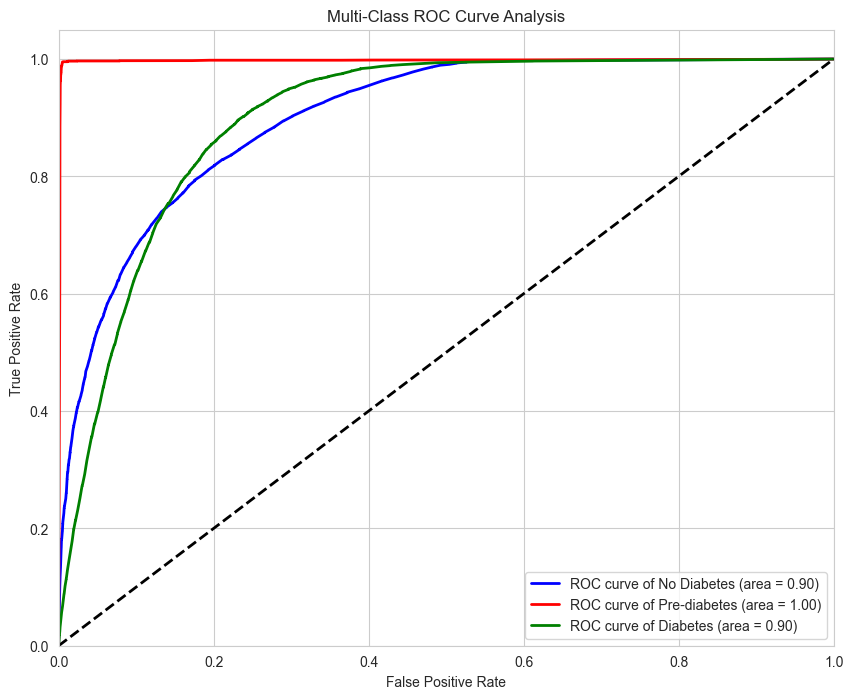


Weighted Average ROC-AUC Score: 0.9327


In [ ]:
print("\n--- DETAILED CLASSIFICATION REPORT ---")
#Precision, Recall, F1, and Supports for each class, plus the Macro and Weighted averages
report = classification_report(y_test, y_pred, target_names=['No Diabetes (0)', 'Pre-diabetes (1)', 'Diabetes (2)'])
print(report)


#Turn the answer '2' into [0, 0, 1]
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

#Probabilities (confidence scores)
y_score = rf_model.predict_proba(X_test)
#Calculate AUC for each class
fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

#Calculate Micro-Average ROC curve (Aggregates all classes)
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

#Plotting
plt.figure(figsize=(10, 8))
colors = cycle(['blue', 'red', 'green'])
classes_names = ['No Diabetes', 'Pre-diabetes', 'Diabetes']

#Plot each class curve
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2,
             label='ROC curve of {0} (area = {1:0.2f})'.format(classes_names[i], roc_auc[i]))

#Plot the "Random Guess" line (dashed)
plt.plot([0, 1], [0, 1], 'k--', lw=2)

plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Multi-Class ROC Curve Analysis')
plt.legend(loc="lower right")
plt.show()

#Print the weighted ROC-AUC score (Single number summary)
auc_score = roc_auc_score(y_test, y_score, multi_class='ovr', average='weighted')
print(f"\nWeighted Average ROC-AUC Score: {auc_score:.4f}")

### Balanced random forest

Original Training Distribution: Counter({0.0: 28277, 1.0: 28277, 2.0: 28276})
Training Balanced Random Forest... (Uses all data across trees)
Training Finished!


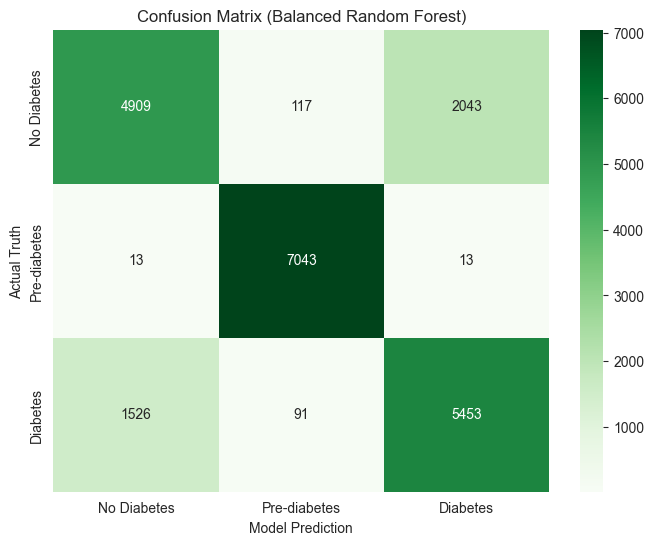

Overall Accuracy: 82.07%
              precision    recall  f1-score   support

 No Diabetes       0.76      0.69      0.73      7069
Pre-diabetes       0.97      1.00      0.98      7069
    Diabetes       0.73      0.77      0.75      7070

    accuracy                           0.82     21208
   macro avg       0.82      0.82      0.82     21208
weighted avg       0.82      0.82      0.82     21208



In [ ]:
print("Original Training Distribution:", Counter(y_train))

#Initialize the Balanced Random Forest
#sampling_strategy='all' ensures it resamples all classes to be equal for each tree
brf_model = BalancedRandomForestClassifier(n_estimators=200, sampling_strategy='all', replacement=True, random_state=42)

print("Training Balanced Random Forest... (Uses all data across trees)")
brf_model.fit(X_train, y_train)
print("Training Finished!")

#Predict
y_pred_brf = brf_model.predict(X_test)

#EVALUATION
cm = confusion_matrix(y_test, y_pred_brf)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=['No Diabetes', 'Pre-diabetes', 'Diabetes'],
            yticklabels=['No Diabetes', 'Pre-diabetes', 'Diabetes'])
plt.title('Confusion Matrix (Balanced Random Forest)')
plt.ylabel('Actual Truth')
plt.xlabel('Model Prediction')
plt.show()

acc = accuracy_score(y_test, y_pred_brf)
print(f"Overall Accuracy: {acc*100:.2f}%")
print(classification_report(y_test, y_pred_brf, target_names=['No Diabetes', 'Pre-diabetes', 'Diabetes']))